In [ ]:
# MQ-2 Telemetry Data Analysis

# This notebook is used to analyze telemetry data collected from an
# ESP32-based MQ-2 gas detection prototype.

In [2]:
%pip install pandas matplotlib

  Using cached matplotlib-3.11.2-cp311-cp311-win_amd64.whl.metadata (80 kB)
  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp311-cp311-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.0 MB 4.2 MB/s eta 0:00:03
   ------ --------------------------------- 1.8/11.0 MB 4.2 MB/s eta 0:00:03
   ---------- ----------------------------- 2.9/11.0 MB 4.3 MB/s eta 0:00:02
   ------------- -------------------------- 3.7/11.0 MB 4.3 MB/s eta 0:00:02
   ----------------- ---------------------- 4.7/11.0 MB 4.3 MB/s eta 0:00:02
   --------------------- ------------------ 5.8/11.0 MB 4.5 MB/s eta 0:00:02
   ------------------------ ------------

In [3]:
# Import Libraries
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

In [6]:
file_path = Path("assets/gas_monitor.csv")

data = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print(f"Number of records: {len(data)}")
print(f"Number of columns: {len(data.columns)}")

Dataset loaded successfully.
Number of records: 125
Number of columns: 5


In [7]:
data.head()

data.tail()

,device_id,sensor,value,gas_status,timestamp
120,GAS-001,MQ-2,0,0,2026-11-23T13:03:35.958825Z
121,GAS-001,MQ-2,0,0,2026-11-23T13:03:42.617687Z
122,GAS-001,MQ-2,0,0,2026-11-23T13:03:42.810080Z
123,GAS-001,MQ-2,0,0,2026-11-23T13:03:44.957090Z
124,GAS-001,MQ-2,0,0,2026-11-23T13:03:46.966994Z


In [8]:
# Inspect dataset structure and data types
print("Dataset shape:")
print(data.shape)

print("\nColumn names:")
print(data.columns.tolist())

Dataset shape:
(125, 5)

Column names:
['device_id', 'sensor', 'value', 'gas_status', 'timestamp']


In [9]:
data.info()

data.describe(include="all")

<class 'pandas.DataFrame'>
RangeIndex: 125 entries, 0 to 124
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   device_id   125 non-null    str  
 1   sensor      125 non-null    str  
 2   value       125 non-null    int64
 3   gas_status  125 non-null    int64
 4   timestamp   125 non-null    str  
dtypes: int64(2), str(3)
memory usage: 5.0 KB


,device_id,sensor,value,gas_status,timestamp
count,125,125,125.000000,125.000000,125
unique,1,1,NaN,NaN,124
top,GAS-001,MQ-2,NaN,NaN,2026-11-23T12:58:51.326879Z
freq,125,125,NaN,NaN,2
mean,NaN,NaN,0.152000,0.152000,NaN
std,NaN,NaN,0.360466,0.360466,NaN
min,NaN,NaN,0.000000,0.000000,NaN
25%,NaN,NaN,0.000000,0.000000,NaN
50%,NaN,NaN,0.000000,0.000000,NaN
75%,NaN,NaN,0.000000,0.000000,NaN


In [10]:
# Check Missing Values
missing_summary = pd.DataFrame({
    "missing_count": data.isnull().sum(),
    "missing_percentage": (
        data.isnull().sum() / len(data) * 100
    )
})

missing_summary

,missing_count,missing_percentage
device_id,0,0.0
sensor,0,0.0
value,0,0.0
gas_status,0,0.0
timestamp,0,0.0


In [12]:
# Check Duplicate Records
duplicate_count = data.duplicated().sum()

print(f"Number of duplicated records: {duplicate_count}")

# Show data duplicates if any
data[data.duplicated(keep=False)]

Number of duplicated records: 1


,device_id,sensor,value,gas_status,timestamp
30,GAS-001,MQ-2,0,0,2026-11-23T12:58:51.326879Z
31,GAS-001,MQ-2,0,0,2026-11-23T12:58:51.326879Z


In [14]:
# Data Cleaning and Preprocessing
clean_data = data.copy()

# Convert timestamp to datetime
clean_data["timestamp"] = pd.to_datetime(
    clean_data["timestamp"],
    errors="coerce"
)

clean_data["timestamp"].head()


# Check timestamp conversion
print(
    "Invalid timestamps:",
    clean_data["timestamp"].isnull().sum()
)

Invalid timestamps: 0


In [16]:
# Convert numeric columns
clean_data["value"] = pd.to_numeric(
    clean_data["value"],
    errors="coerce"
)

clean_data["gas_status"] = pd.to_numeric(
    clean_data["gas_status"],
    errors="coerce"
)

clean_data.dtypes

device_id                     str
sensor                        str
value                       int64
gas_status                  int64
timestamp     datetime64[us, UTC]
dtype: object

In [17]:
# Remove invalid records
before_cleaning = len(clean_data)

clean_data = clean_data.dropna(
    subset=["timestamp", "value"]
)

clean_data = clean_data.drop_duplicates()

clean_data = clean_data.sort_values(
    "timestamp"
).reset_index(drop=True)

after_cleaning = len(clean_data)

print(f"Records before cleaning: {before_cleaning}")
print(f"Records after cleaning : {after_cleaning}")
print(f"Records removed        : {before_cleaning - after_cleaning}")

Records before cleaning: 125
Records after cleaning : 124
Records removed        : 1


In [18]:
# Exploratory Data Analysis (EDA)
print("Sensors recorded:")
print(clean_data["sensor"].value_counts())

print("Unique sensor types:")
print(clean_data["sensor"].unique())

Sensors recorded:
sensor
MQ-2    124
Name: count, dtype: int64
Unique sensor types:
<StringArray>
['MQ-2']
Length: 1, dtype: str


In [20]:
# Gas Status Distribution
gas_status_counts = (
    clean_data["gas_status"]
    .value_counts()
    .sort_index()
)

gas_status_counts

# Persentage Distribution of Gas Status
gas_status_percentage = (
    clean_data["gas_status"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

gas_status_percentage

gas_status
0    84.677419
1    15.322581
Name: proportion, dtype: float64

In [21]:
# MQ-2 Value Statistics
clean_data["value"].describe()

count    124.000000
mean       0.153226
std        0.361666
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        1.000000
Name: value, dtype: float64

In [22]:
clean_data["value"].value_counts().sort_index()

value
0    105
1     19
Name: count, dtype: int64

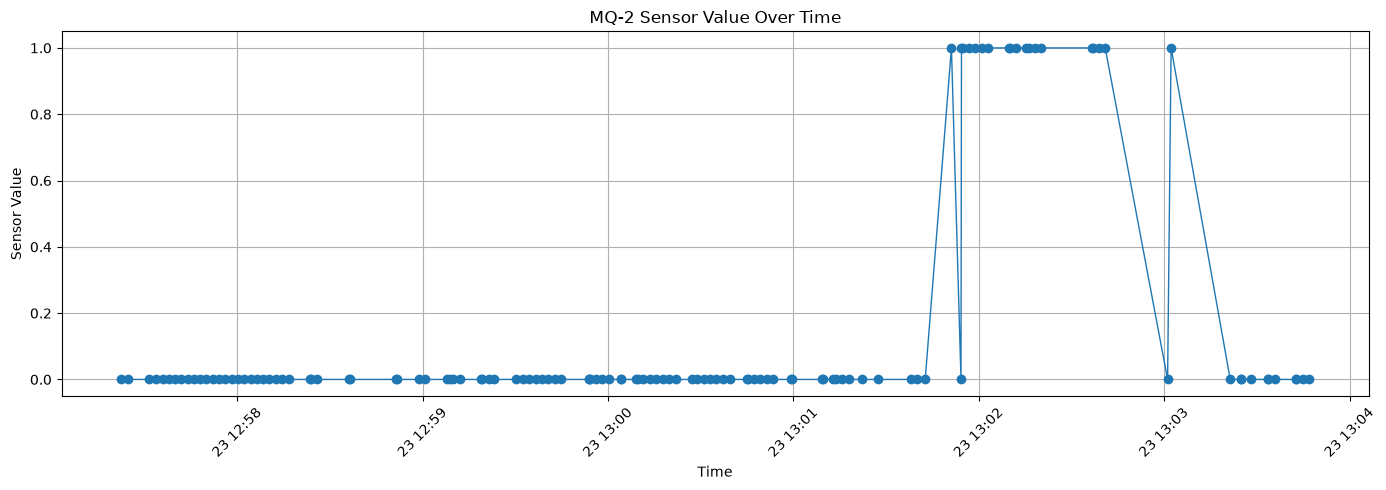

In [23]:
# MQ-2 value over time
plt.figure(figsize=(14, 5))

plt.plot(
    clean_data["timestamp"],
    clean_data["value"],
    marker="o",
    linewidth=1
)

plt.title("MQ-2 Sensor Value Over Time")
plt.xlabel("Time")
plt.ylabel("Sensor Value")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

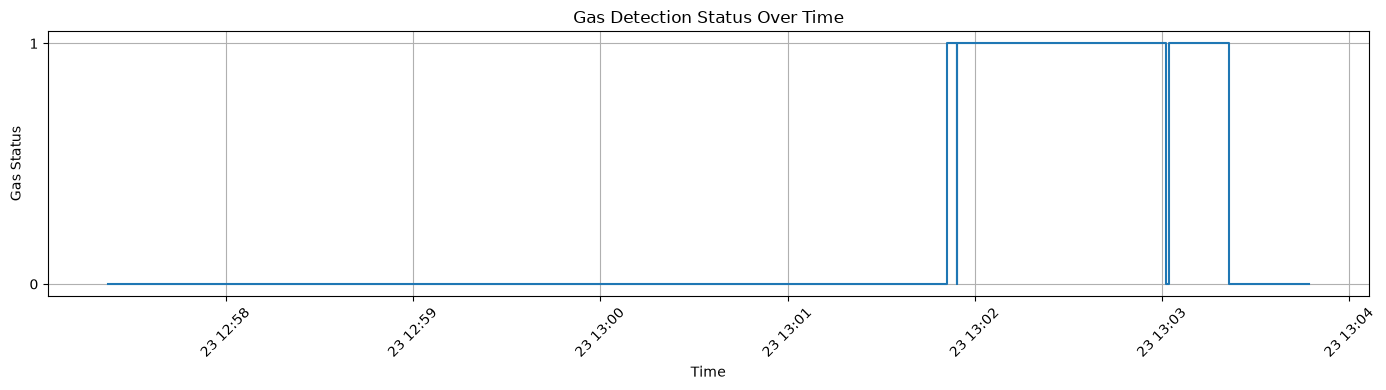

In [24]:
# Gas Detection Status Over Time
plt.figure(figsize=(14, 4))

plt.step(
    clean_data["timestamp"],
    clean_data["gas_status"],
    where="post"
)

plt.title("Gas Detection Status Over Time")
plt.xlabel("Time")
plt.ylabel("Gas Status")

plt.yticks([0, 1])

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

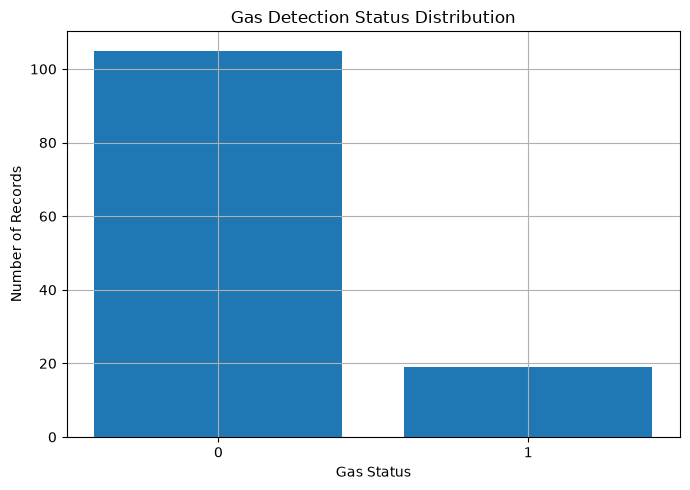

In [25]:
# Gas Status Distribution
plt.figure(figsize=(7, 5))

plt.bar(
    gas_status_counts.index.astype(str),
    gas_status_counts.values
)

plt.title("Gas Detection Status Distribution")
plt.xlabel("Gas Status")
plt.ylabel("Number of Records")

plt.tight_layout()

plt.show()

<Figure size 800x500 with 0 Axes>

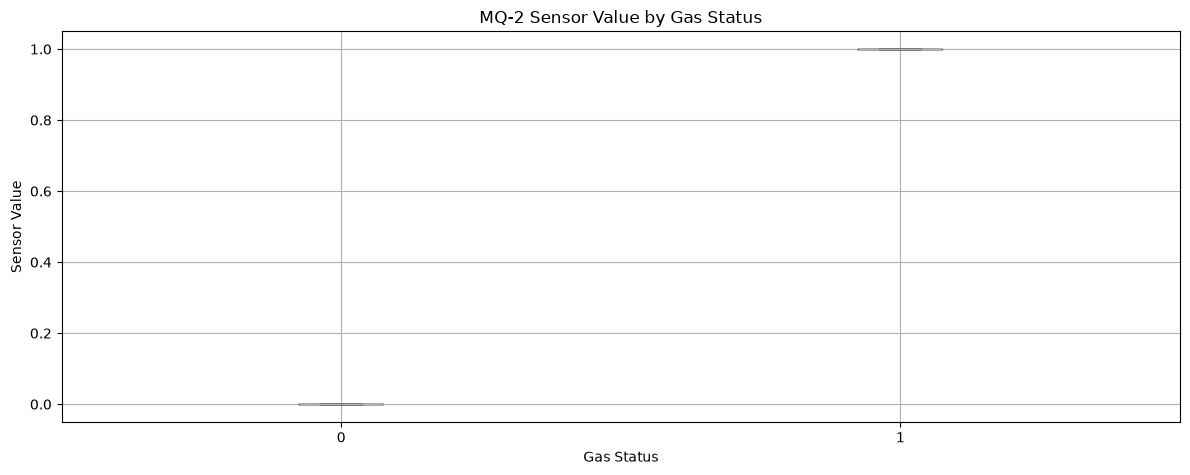

In [26]:
# Sensor value by gas status
plt.figure(figsize=(8, 5))

clean_data.boxplot(
    column="value",
    by="gas_status"
)

plt.title("MQ-2 Sensor Value by Gas Status")
plt.suptitle("")

plt.xlabel("Gas Status")
plt.ylabel("Sensor Value")

plt.tight_layout()

plt.show()

In [27]:
# Calculate sensor value changes
clean_data["value_change"] = (
    clean_data["value"].diff()
)

clean_data[
    [
        "timestamp",
        "value",
        "value_change",
        "gas_status"
    ]
].head(20)

,timestamp,value,value_change,gas_status
0,2026-11-23 12:57:22.361532+00:00,0,NaN,0
1,2026-11-23 12:57:24.579191+00:00,0,0.0,0
2,2026-11-23 12:57:31.558285+00:00,0,0.0,0
3,2026-11-23 12:57:33.628556+00:00,0,0.0,0
4,2026-11-23 12:57:35.845169+00:00,0,0.0,0
5,2026-11-23 12:57:37.831051+00:00,0,0.0,0
6,2026-11-23 12:57:39.771867+00:00,0,0.0,0
7,2026-11-23 12:57:41.828633+00:00,0,0.0,0
8,2026-11-23 12:57:43.972152+00:00,0,0.0,0
9,2026-11-23 12:57:45.880211+00:00,0,0.0,0


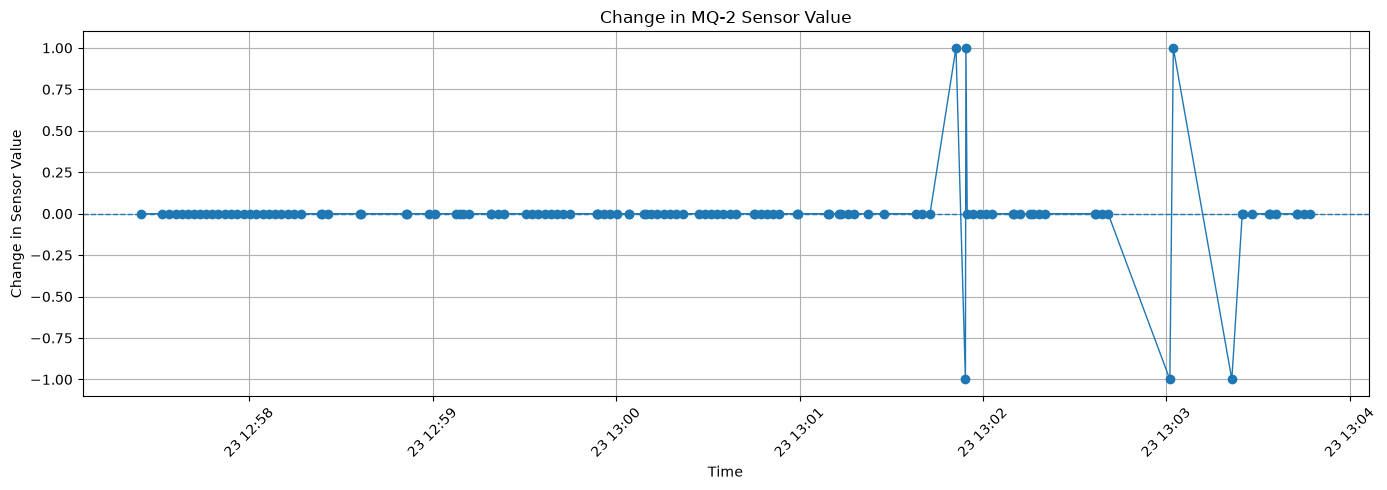

In [28]:
plt.figure(figsize=(14, 5))

plt.plot(
    clean_data["timestamp"],
    clean_data["value_change"],
    marker="o",
    linewidth=1
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Change in MQ-2 Sensor Value")
plt.xlabel("Time")
plt.ylabel("Change in Sensor Value")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [29]:
# Clean dataset
output_file = Path("gas_monitor_clean.csv")

clean_data.to_csv(
    output_file,
    index=False
)

print(f"Cleaned dataset saved to: {output_file}")

Cleaned dataset saved to: gas_monitor_clean.csv
